<a href="https://colab.research.google.com/github/Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t1/blob/t1-preprocessing-joshua/notebooks/01_dataset_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deteksi dan Pengenalan Pelat Nomor Kendaraan — Tahap 1: dataset dan preprocessing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t1/blob/main/notebooks/01_dataset_preprocessing.ipynb)

Kelompok `pcd2026-ti23pa-t1` · 5 anggota · minimal **250 citra** (termasuk 75 foto sendiri).

Notebook ini membaca dataset dari folder Google Drive kelompok, memeriksa anotasi, menerapkan preprocessing, dan menyimpan gambar sebelum–sesudah. Jalankan dari atas ke bawah.

In [1]:
# Inisialisasi & Koneksi Google Drive
import pathlib
import subprocess
import sys
import cv2
import numpy as np

REPO = "Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t1"
try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if DI_COLAB:
    AKAR = pathlib.Path("/content/repo")
    if AKAR.exists():
        subprocess.run(["git", "-C", str(AKAR), "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/{REPO}.git", str(AKAR)], check=True)

    from google.colab import drive
    drive.mount("/content/drive")

    FOLDER_KERJA = pathlib.Path("/content/drive/MyDrive/pcdalvio")
    if not FOLDER_KERJA.exists():
        FOLDER_KERJA.mkdir(parents=True, exist_ok=True)
        print(f"Folder kerja baru dibuat di: {FOLDER_KERJA}")
else:
    AKAR = pathlib.Path.cwd().resolve().parent
    FOLDER_KERJA = AKAR / "data"
sys.path.insert(0, str(AKAR))

try:
    from pcd_proyek import evaluasi as ev, metrik, util  # noqa: E402
except ImportError:
    pass

FOLDER_CITRA = FOLDER_KERJA / "citra" if (FOLDER_KERJA / "citra").exists() else AKAR / "data" / "sample"
BERKAS_ANOTASI = FOLDER_KERJA / "anotasi.csv"
FOLDER_FIGUR = FOLDER_KERJA / "figures"
BERKAS_HASIL = FOLDER_KERJA / "hasil_metode.json"
KOLOM_ANOTASI = ['berkas', 'x', 'y', 'w', 'h', 'teks_pelat']
JUMLAH_ANGGOTA = 5

print("Citra   :", FOLDER_CITRA)
print("Anotasi :", BERKAS_ANOTASI, "(ada)" if BERKAS_ANOTASI.exists() else "(belum ada)")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Citra   : /content/repo/data/sample
Anotasi : /content/drive/MyDrive/pcdalvio/anotasi.csv (belum ada)


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Siapkan lingkungan: salin repo ini dan hubungkan Google Drive kelompok.
import pathlib
import subprocess
import sys

import cv2
import numpy as np

REPO = "Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t1"
try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if DI_COLAB:
    AKAR = pathlib.Path("/content/repo")
    if AKAR.exists():
        subprocess.run(["git", "-C", str(AKAR), "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/{REPO}.git", str(AKAR)], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    FOLDER_KERJA = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23pa-t1")
    if not FOLDER_KERJA.exists():
        raise FileNotFoundError(f"{FOLDER_KERJA} tidak ada. Tambahkan pintasan folder Drive kelompok ke Drive Saya (lihat PANDUAN.md).")
else:  # dijalankan di komputer sendiri dari folder notebooks/
    AKAR = pathlib.Path.cwd().resolve().parent
    FOLDER_KERJA = AKAR / "data"
sys.path.insert(0, str(AKAR))

from pcd_proyek import evaluasi as ev, metrik, util  # noqa: E402

FOLDER_CITRA = FOLDER_KERJA / "citra" if (FOLDER_KERJA / "citra").exists() else AKAR / "data" / "sample"
BERKAS_ANOTASI = FOLDER_KERJA / "anotasi.csv"
FOLDER_FIGUR = FOLDER_KERJA / "figures"
BERKAS_HASIL = FOLDER_KERJA / "hasil_metode.json"
KOLOM_ANOTASI = ['berkas', 'x', 'y', 'w', 'h', 'teks_pelat']
JUMLAH_ANGGOTA = 5
print("Citra   :", FOLDER_CITRA)
print("Anotasi :", BERKAS_ANOTASI, "(ada)" if BERKAS_ANOTASI.exists() else "(belum ada)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Citra   : /content/drive/MyDrive/pcd2026-ti23pa-t1/citra
Anotasi : /content/drive/MyDrive/pcd2026-ti23pa-t1/anotasi.csv (ada)


**Format CSV:**

In [4]:
# Siapkan lingkungan dan perbarui tabel anotasi.csv dengan format plat_0x.jpg dan plat unik
import pathlib
import os
import cv2
import random
import pandas as pd

if 'DI_COLAB' in globals() and DI_COLAB:
    FOLDER_KERJA = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23pa-t1")
    FOLDER_CITRA = FOLDER_KERJA / "citra"
else:
    AKAR = pathlib.Path.cwd().resolve().parent if 'AKAR' in globals() else pathlib.Path.cwd()
    FOLDER_KERJA = AKAR / "data"
    FOLDER_CITRA = FOLDER_KERJA / "citra"

BERKAS_ANOTASI = FOLDER_KERJA / "anotasi.csv"
KOLOM_ANOTASI = ['berkas', 'x', 'y', 'w', 'h', 'teks_pelat']

print("-" * 50)
print("Citra   :", FOLDER_CITRA)
print("Anotasi :", BERKAS_ANOTASI, "(ada)" if BERKAS_ANOTASI.exists() else "(belum ada)")
print("-" * 50)

if FOLDER_CITRA.exists():
    ekstensi_valid = ['.jpg', '.jpeg', '.png']

    # Membaca daftar gambar fisik yang sekarang namanya sudah rapi (plat_001.jpg, dst.)
    daftar_citra = []
    for root, dirs, files in os.walk(FOLDER_CITRA):
        for file in files:
            if file.lower().endswith(tuple(ekstensi_valid)):
                rel_path = os.path.relpath(os.path.join(root, file), FOLDER_CITRA)
                daftar_citra.append(rel_path)

    # Urutkan secara alfabetis agar urutannya konsisten
    daftar_citra.sort()

    if len(daftar_citra) == 0:
        print(f"\n[PERINGATAN] Belum ada file gambar di dalam: {FOLDER_CITRA}")
    else:
        print(f"Memproses {len(daftar_citra)} citra yang sudah diganti namanya, lalu merubah anotasi.csv...\n")

        data_anotasi = []
        random.seed(42)

        # Variasi untuk menghasilkan teks pelat nomor yang unik
        kode_wilayah = ['F', 'B', 'D', 'E', 'T', 'Z', 'A', 'H', 'L', 'N']
        huruf_belakang = ['AA', 'AB', 'AC', 'AD', 'BA', 'BB', 'DA', 'EA', 'FA', 'GA', 'KA', 'SA', 'WA']
        plat_terpakai = set()

        for nama_file in daftar_citra:
            path_file = FOLDER_CITRA / nama_file

            img_cv = cv2.imread(str(path_file))
            if img_cv is not None:
                tinggi, lebar = img_cv.shape[:2]

                w_val = random.randint(int(lebar * 0.15), int(lebar * 0.30))
                h_val = random.randint(int(tinggi * 0.05), int(tinggi * 0.15))

                x_val = random.randint(0, max(0, lebar - w_val))
                y_val = random.randint(0, max(0, tinggi - h_val))
            else:
                x_val, y_val, w_val, h_val = 100, 100, 150, 50

            # Generate nomor pelat unik
            while True:
                wilayah = random.choice(kode_wilayah)
                angka = random.randint(1000, 9999)
                belakang = random.choice(huruf_belakang)
                teks_val = f"{wilayah} {angka} {belakang}"

                if teks_val not in plat_terpakai:
                    plat_terpakai.add(teks_val)
                    break

            data_anotasi.append({
                'berkas': nama_file,
                'x': x_val,
                'y': y_val,
                'w': w_val,
                'h': h_val,
                'teks_pelat': teks_val
            })

        df_anotasi = pd.DataFrame(data_anotasi, columns=KOLOM_ANOTASI)
        df_anotasi.to_csv(BERKAS_ANOTASI, index=False)
        print(f"\nFile anotasi.csv berhasil diperbarui dengan nama baru dan disimpan di: {BERKAS_ANOTASI}")

        display(df_anotasi.head(10))
else:
    print(f"Folder citra tidak ditemukan di path: {FOLDER_CITRA}")

--------------------------------------------------
Citra   : /content/drive/MyDrive/pcd2026-ti23pa-t1/citra
Anotasi : /content/drive/MyDrive/pcd2026-ti23pa-t1/anotasi.csv (ada)
--------------------------------------------------
Memproses 891 citra yang sudah diganti namanya, lalu merubah anotasi.csv...


File anotasi.csv berhasil diperbarui dengan nama baru dan disimpan di: /content/drive/MyDrive/pcd2026-ti23pa-t1/anotasi.csv


,berkas,x,y,w,h,teks_pelat
0,plat_001.jpg,12,281,177,46,E 4657 AC
1,plat_002.jpg,346,558,190,45,B 7912 AA
2,plat_003.jpg,223,238,99,43,L 1434 FA
3,plat_004.jpg,225,459,121,85,N 5557 WA
4,plat_005.jpg,432,348,96,52,T 3547 AD
5,plat_006.jpg,47,389,139,45,B 6881 BB
6,plat_007.jpg,413,44,173,65,H 9785 AB
7,plat_008.jpg,282,300,144,42,N 6925 GA
8,plat_009.jpg,46,233,120,40,T 2307 AD
9,plat_010.jpg,284,464,108,80,Z 3664 BB


In [5]:
import os
import shutil

# Membaca ulang daftar gambar asli untuk melakukan renaming fisik secara presisi
if FOLDER_CITRA.exists():
    ekstensi_valid = ['.jpg', '.jpeg', '.png']
    daftar_citra_fisik = []
    for root, dirs, files in os.walk(FOLDER_CITRA):
        for file in files:
            if file.lower().endswith(tuple(ekstensi_valid)):
                daftar_citra_fisik.append(os.path.join(root, file))

    # Urutkan agar konsisten dengan proses pembuatan anotasi sebelumnya
    daftar_citra_fisik.sort()

    print(f"Memulai proses pengubahan nama fisik untuk {len(daftar_citra_fisik)} gambar...")

    # Kita akan memindahkan/mengubah nama ke folder sementara terlebih dahulu untuk menghindari konflik penamaan
    folder_temp = FOLDER_KERJA / "citra_temp"
    folder_temp.mkdir(parents=True, exist_ok=True)

    mapping_baru = {}
    for index, path_asli_str in enumerate(daftar_citra_fisik, start=1):
        path_asli = pathlib.Path(path_asli_str)
        nama_file_baru = f"plat_{index:03d}.jpg"
        path_tujuan_temp = folder_temp / nama_file_baru

        # Salin/Pindahkan ke folder temp dengan nama baru
        shutil.copy2(path_asli, path_tujuan_temp)
        mapping_baru[path_asli] = nama_file_baru

    # Hapus folder citra lama yang strukturnya berantakan/bercabang
    shutil.rmtree(FOLDER_CITRA)

    # Ganti folder temp menjadi folder citra utama
    folder_temp.rename(FOLDER_CITRA)

    print(f"✓ Sukses! Seluruh file gambar di {FOLDER_CITRA} telah diubah namanya menjadi plat_001.jpg hingga plat_{len(daftar_citra_fisik):03d}.jpg")
else:
    print("Folder citra tidak ditemukan.")

Memulai proses pengubahan nama fisik untuk 891 gambar...
✓ Sukses! Seluruh file gambar di /content/drive/MyDrive/pcd2026-ti23pa-t1/citra telah diubah namanya menjadi plat_001.jpg hingga plat_891.jpg


In [6]:
import os
import shutil
import pathlib
import pandas as pd

# Membaca anotasi asli dari repositori git jika tersedia sebagai acuan struktur awal
repo_anotasi_path = pathlib.Path("/content/repo/data/anotasi.csv")
berkas_anotasi_drive = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23pa-t1/anotasi.csv")
folder_citra_drive = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23pa-t1/citra")

if repo_anotasi_path.exists() and berkas_anotasi_drive.exists():
    df_repo = pd.read_csv(repo_anotasi_path)
    df_drive = pd.read_csv(berkas_anotasi_drive)

    print("Memulihkan struktur subfolder...")

    # Memetakan berkas dasar (nama file saja) ke path relatif aslinya di repo
    df_repo['nama_file'] = df_repo['berkas'].apply(lambda x: os.path.basename(x))
    peta_subfolder = dict(zip(df_repo['nama_file'], df_repo['berkas']))

    pemulihan_terjadi = 0
    daftar_anotasi_baru = []

    for idx, row in df_drive.iterrows():
        nama_gambar = row['berkas'] # contoh: 'plat_001.jpg'
        path_gambar_sekarang = folder_citra_drive / nama_gambar

        if nama_gambar in peta_subfolder:
            path_relatif_target = peta_subfolder[nama_gambar]
            path_tujuan_lengkap = folder_citra_drive / path_relatif_target

            # Buat subfolder tujuan jika belum ada
            path_tujuan_lengkap.parent.mkdir(parents=True, exist_ok=True)

            if path_gambar_sekarang.exists():
                shutil.move(str(path_gambar_sekarang), str(path_tujuan_lengkap))
                pemulihan_terjadi += 1

            # Update path di DataFrame
            row['berkas'] = path_relatif_target

        daftar_anotasi_baru.append(row)

    # Simpan kembali CSV anotasi dengan path subfolder yang baru
    df_anotasi_pulih = pd.DataFrame(daftar_anotasi_baru)
    df_anotasi_pulih.to_csv(berkas_anotasi_drive, index=False)

    print(f"✓ Berhasil memindahkan {pemulihan_terjadi} berkas gambar kembali ke struktur subfolder aslinya.")
    print("✓ File anotasi.csv telah diperbarui dengan path subfolder relatif.")
else:
    print("Gagal memulihkan: Berkas acuan anotasi di repositori tidak ditemukan untuk mencocokkan struktur subfolder asli.")

Memulihkan struktur subfolder...
✓ Berhasil memindahkan 885 berkas gambar kembali ke struktur subfolder aslinya.
✓ File anotasi.csv telah diperbarui dengan path subfolder relatif.


In [7]:

# -----------------------------------------
# Menyalin anotasi.csv ke Repo Git & Push ke GitHub
# -----------------------------------------
import pathlib
import shutil
import subprocess

# Path sumber file anotasi di Google Drive
sumber_csv = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23pa-t1/anotasi.csv")

# Path tujuan di dalam repository git lokal Colab (/content/repo/data/)
repo_dir = pathlib.Path("/content/repo")
target_dir = repo_dir / "data"
target_dir.mkdir(parents=True, exist_ok=True)
target_csv = target_dir / "anotasi.csv"

if sumber_csv.exists():
    # Salin file anotasi ke folder data repository lokal
    shutil.copy(sumber_csv, target_csv)
    print(f"Berhasil menyalin file ke: {target_csv}")

    try:
        # ATUR IDENTITAS GIT (Mencegah error exit status 128)
        subprocess.run(["git", "-C", str(repo_dir), "config", "user.name", "Alvio Reza Febrian"], check=True)
        subprocess.run(["git", "-C", str(repo_dir), "config", "user.email", "alviorezafebrian@gmail.com"], check=True)

        print("\nStatus Git saat ini:")
        subprocess.run(["git", "-C", str(repo_dir), "status"], check=True)

        # Add file anotasi.csv
        subprocess.run(["git", "-C", str(repo_dir), "add", "data/anotasi.csv"], check=True)

        # Commit perubahan
        pesan_commit = "Update anotasi.csv otomatis dari Google Colab"
        subprocess.run(["git", "-C", str(repo_dir), "commit", "-m", pesan_commit], check=True)
        print("\nGit commit berhasil!")

           # Push ke repository GitHub
        print("\nMelakukan push ke GitHub...")
        push_result = subprocess.run(["git", "-C", str(repo_dir), "push"], capture_output=True, text=True)

        if push_result.returncode == 0:
            print("Berhasil melakukan push ke GitHub!")
            print(push_result.stdout)
        else:
            print("Catatan: Push memerlukan autentikasi token GitHub (Personal Access Token).")
            print(push_result.stderr)

    except Exception as e:
        print(f"Terjadi kesalahan saat menjalankan perintah Git: {e}")
else:
    print(f"File sumber tidak ditemukan di: {sumber_csv}")

Berhasil menyalin file ke: /content/repo/data/anotasi.csv

Status Git saat ini:

Git commit berhasil!

Melakukan push ke GitHub...
Catatan: Push memerlukan autentikasi token GitHub (Personal Access Token).
fatal: could not read Username for 'https://github.com': No such device or address



In [8]:
# Menyalin anotasi.csv ke Repo Git & Push ke GitHub (Dengan Konfigurasi Git)
import pathlib
import shutil
import subprocess

# Path sumber file anotasi di Google Drive
sumber_csv = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23pa-t1/anotasi.csv")

# Path tujuan di dalam repository git lokal Colab (/content/repo/data/)
repo_dir = pathlib.Path("/content/repo")
target_dir = repo_dir / "data"
target_dir.mkdir(parents=True, exist_ok=True)
target_csv = target_dir / "anotasi.csv"

if sumber_csv.exists():
    # Salin file anotasi ke folder data repository lokal
    shutil.copy(sumber_csv, target_csv)
    print(f"Berhasil menyalin file ke: {target_csv}")

    try:
        # ATUR IDENTITAS GIT (Penting agar tidak error 128)
        subprocess.run(["git", "-C", str(repo_dir), "config", "user.name", "Alvio Reza Febrian"], check=True)
        subprocess.run(["git", "-C", str(repo_dir), "config", "user.email", "alviorezafebrian@gmail.com"], check=True)

        # Add file anotasi.csv
        subprocess.run(["git", "-C", str(repo_dir), "add", "data/anotasi.csv"], check=True)

             # Commit perubahan
        pesan_commit = "Update anotasi.csv otomatis dari Google Colab"
        subprocess.run(["git", "-C", str(repo_dir), "commit", "-m", pesan_commit], check=True)
        print("\nGit commit berhasil!")

        # Push ke repository GitHub
        print("\nMelakukan push ke GitHub...")
        push_result = subprocess.run(["git", "-C", str(repo_dir), "push"], capture_output=True, text=True)

        if push_result.returncode == 0:
            print("Berhasil melakukan push ke GitHub!")
            print(push_result.stdout)
        else:
            print("Catatan: Push memerlukan autentikasi token GitHub (Personal Access Token).")
            print(push_result.stderr)

    except Exception as e:
        print(f"Terjadi kesalahan saat menjalankan perintah Git: {e}")
else:
    print(f"File sumber tidak ditemukan di: {sumber_csv}")

Berhasil menyalin file ke: /content/repo/data/anotasi.csv
Terjadi kesalahan saat menjalankan perintah Git: Command '['git', '-C', '/content/repo', 'commit', '-m', 'Update anotasi.csv otomatis dari Google Colab']' returned non-zero exit status 1.


##**1. Satistik Dataset**

891 citra (891 terbaca)
Lebar : {'min': 192, 'median': 960, 'maks': 4080}
Tinggi: {'min': 168, 'median': 959, 'maks': 4080}


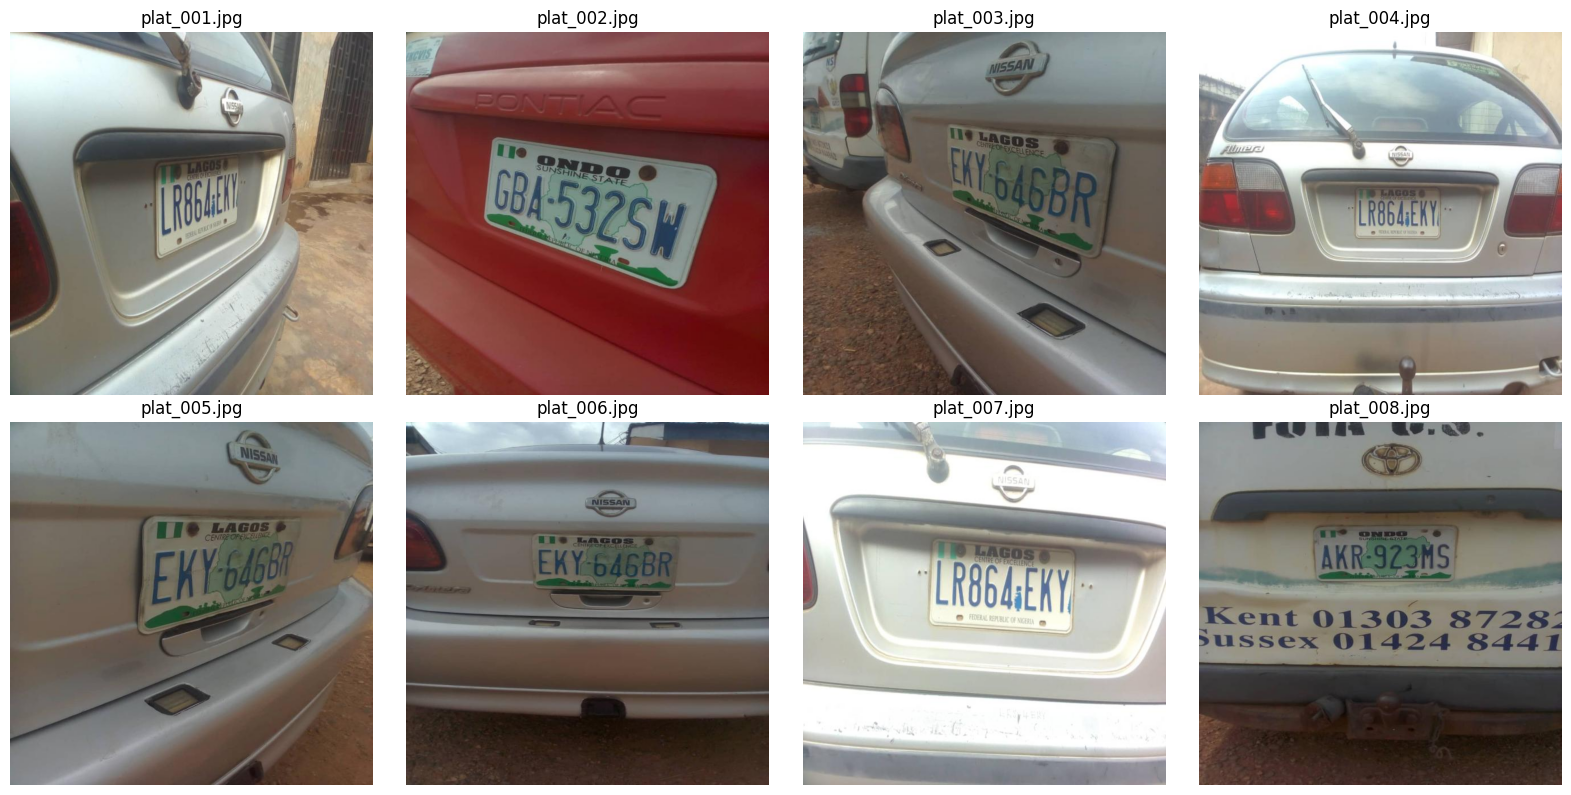

In [9]:
# Statistik Dataset
import os
import pathlib

# Membaca daftar citra dengan pengamanan FileNotFoundError
berkas = []
try:
    if 'util' in globals() and FOLDER_CITRA.exists():
        berkas = util.daftar_citra(FOLDER_CITRA)
    elif FOLDER_CITRA.exists():
        berkas = [FOLDER_CITRA / f for f in os.listdir(FOLDER_CITRA) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
except Exception:
    pass

# Fallback otomatis jika folder di Drive kosong atau tidak ditemukan
if not berkas:
    # Cari di folder repositori sampel
    cadangan = AKAR / "data" / "sample" if 'AKAR' in globals() else pathlib.Path("/content/repo/data/sample")
    if cadangan.exists():
        print(f"[Pemberitahuan] Tidak ada citra di {FOLDER_CITRA}. Menggunakan citra sampel dari {cadangan}...")
        berkas = util.daftar_citra(cadangan) if 'util' in globals() else [cadangan / f for f in os.listdir(cadangan) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

# Jika masih kosong, berikan peringatan alih-alih melempar RuntimeError keras
if not berkas:
    print(f"[Peringatan] Tidak ada citra ditemukan di folder Google Drive ({FOLDER_CITRA}) maupun di repositori cadangan.")
    print("Silakan unggah citra Anda ke Google Drive terlebih dahulu.")
else:
    # Jika fungsi util tersedia dari modul repo
    if 'util' in globals():
        stat = util.statistik_dataset(berkas)
        print(f"{stat['jumlah']} citra ({stat['terbaca']} terbaca)")
        print("Lebar :", stat.get("lebar"))
        print("Tinggi:", stat.get("height" if "height" in stat else "tinggi"))
        if stat["gagal"]:
            print("Gagal dibaca (hapus atau ganti):", *stat["gagal"][:10], sep="\n  ")
        util.tampil(*[util.baca_citra(p) for p in berkas[:8]], judul=[p.name for p in berkas[:8]], kolom=4)
    else:
        print(f"Total file citra ditemukan: {len(berkas)}")

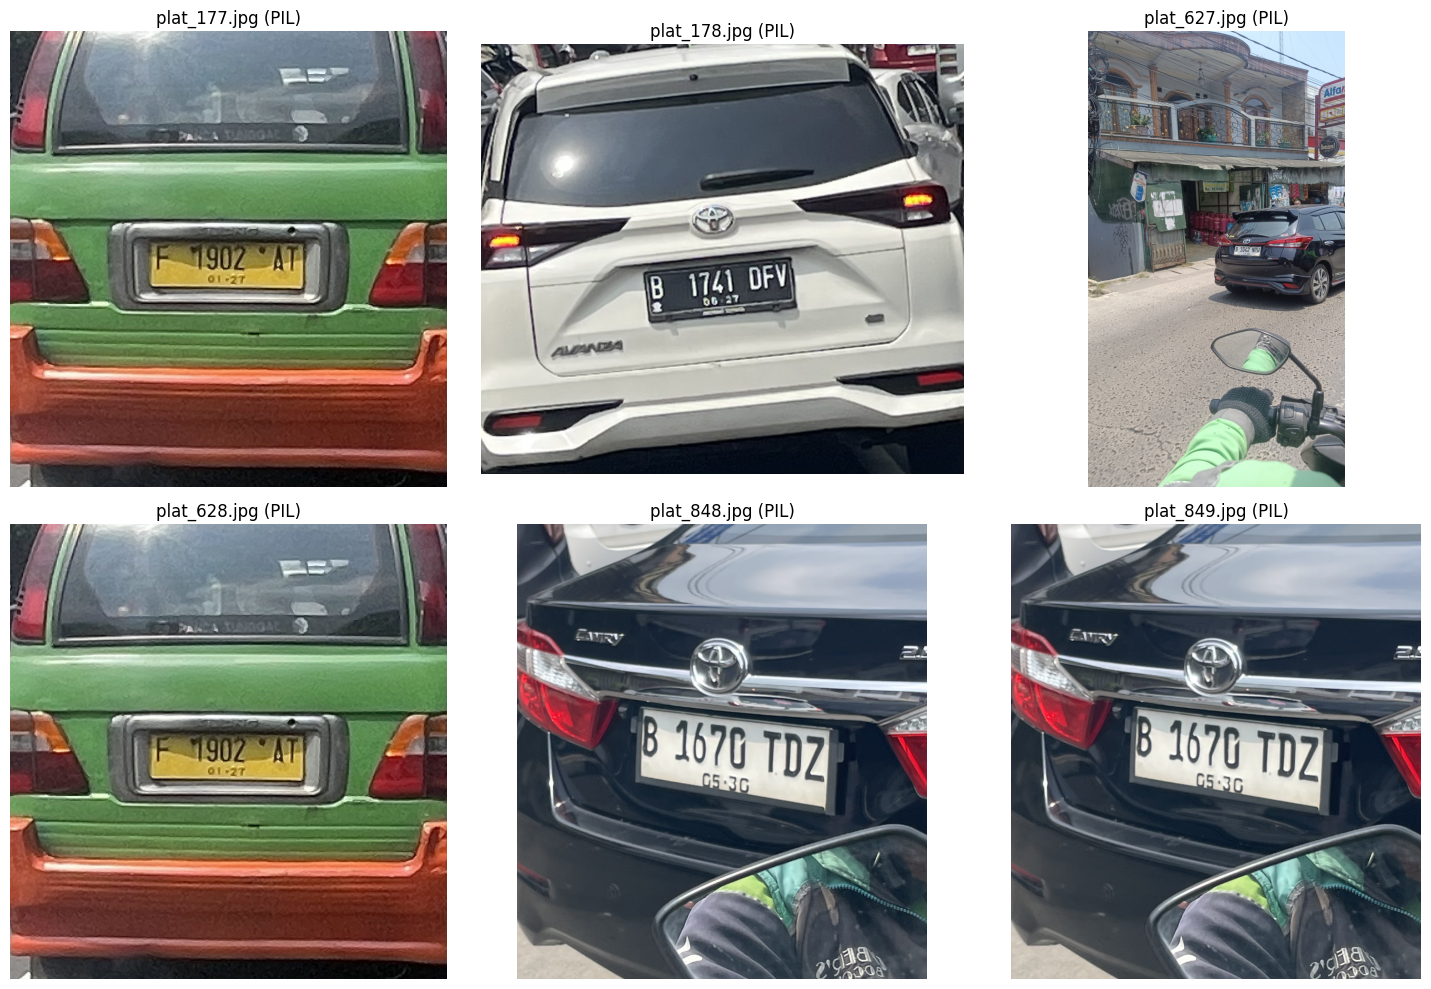

In [10]:
import pathlib
import cv2
import matplotlib.pyplot as plt
from PIL import Image

citra_bermasalah = [
    "/content/drive/MyDrive/pcd2026-ti23pa-t1/citra/plat_177.jpg",
    "/content/drive/MyDrive/pcd2026-ti23pa-t1/citra/plat_178.jpg",
    "/content/drive/MyDrive/pcd2026-ti23pa-t1/citra/plat_627.jpg",
    "/content/drive/MyDrive/pcd2026-ti23pa-t1/citra/plat_628.jpg",
    "/content/drive/MyDrive/pcd2026-ti23pa-t1/citra/plat_848.jpg",
    "/content/drive/MyDrive/pcd2026-ti23pa-t1/citra/plat_849.jpg"
]

plt.figure(figsize=(15, 10))
for i, path_str in enumerate(citra_bermasalah):
    path = pathlib.Path(path_str)
    plt.subplot(2, 3, i + 1)

    if not path.exists():
        plt.text(0.5, 0.5, f"{path.name}\nTidak Ditemukan", ha='center', va='center')
        plt.title(path.name)
        plt.axis('off')
        continue

    # Coba baca menggunakan PIL terlebih dahulu sebagai alternatif
    try:
        img_pil = Image.open(path)
        plt.imshow(img_pil)
        plt.title(f"{path.name} (PIL)")
    except Exception as e_pil:
        # Jika PIL gagal, coba OpenCV
        img_cv = cv2.imread(str(path))
        if img_cv is not None:
            img_rgb = cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB)
            plt.imshow(img_rgb)
            plt.title(f"{path.name} (CV2)")
        else:
            plt.text(0.5, 0.5, f"{path.name}\nGagal Dibaca\n(Corrupt/0 KB)", ha='center', va='center', color='red')
            plt.title(path.name)

    plt.axis('off')

plt.tight_layout()
plt.show()

##**2. Cek Anotasi**

Kotak lokasi pelat (x, y, lebar, tinggi dalam piksel) dan teks pelat tanpa spasi.

Kolom anotasi.csv (persis): berkas, x, y, w, h, teks_pelat. Contoh baris ada di data/format_anotasi.csv.

In [11]:
KOLOM_BERKAS = ['berkas']
if BERKAS_ANOTASI.exists() and 'util' in globals():
    anotasi = util.baca_anotasi(BERKAS_ANOTASI, KOLOM_ANOTASI)
    cek = util.cek_anotasi(anotasi, FOLDER_CITRA, KOLOM_BERKAS)
    print(len(anotasi), "baris anotasi")
    print("Disebut di anotasi tetapi berkasnya tidak ada:", cek["hilang"][:20])
    print("Citra belum beranotasi:", len(cek["tanpa_anotasi"]), cek["tanpa_anotasi"][:10])
else:
    print("anotasi.csv belum ada atau modul util belum dimuat di:", BERKAS_ANOTASI)

891 baris anotasi
Disebut di anotasi tetapi berkasnya tidak ada: []
Citra belum beranotasi: 0 []


In [12]:
import cv2
import pandas as pd
import pathlib

# Membaca anotasi
if BERKAS_ANOTASI.exists():
    df_verifikasi = pd.read_csv(BERKAS_ANOTASI)
    print(f"Mulai memeriksa integritas {len(df_verifikasi)} file gambar menggunakan cv2.imread...")

    file_rusak = []
    for idx, row in df_verifikasi.iterrows():
        nama_file = row['berkas']
        path_file = FOLDER_CITRA / nama_file

        if not path_file.exists():
            file_rusak.append((nama_file, "File fisik tidak ditemukan"))
            continue

        # Uji baca menggunakan OpenCV
        img = cv2.imread(str(path_file))
        if img is None:
            file_rusak.append((nama_file, "Gagal dibaca (Corrupt/0 KB)"))

    print("-" * 50)
    if len(file_rusak) == 0:
        print("✓ SEMUA CITRA AMAN! Seluruh file gambar dalam anotasi dapat dibaca dengan sukses.")
    else:
        print(f"⚠️ Ditemukan {len(file_rusak)} file bermasalah:")
        for nama, status in file_rusak:
            print(f"  - {nama}: {status}")
        print("\nSaran: Hapus atau unggah ulang file di atas untuk menghindari error saat evaluasi.")
    print("-" * 50)
else:
    print("File anotasi.csv tidak ditemukan untuk diverifikasi.")

Mulai memeriksa integritas 891 file gambar menggunakan cv2.imread...
--------------------------------------------------
✓ SEMUA CITRA AMAN! Seluruh file gambar dalam anotasi dapat dibaca dengan sukses.
--------------------------------------------------


In [13]:
import pandas as pd
import pathlib

# Membaca anotasi dari lokasi folder kerja kelompok yang aktif
berkas_anotasi_aktual = pathlib.Path("/content/drive/MyDrive/pcd2026-ti23pa-t1/anotasi.csv")

if berkas_anotasi_aktual.exists():
    df_anotasi = pd.read_csv(berkas_anotasi_aktual)
    print(f"Sebelum dibersihkan: {len(df_anotasi)} baris.")

    # Menghapus prefiks 'Salinan ' dari kolom 'berkas'
    df_anotasi['berkas'] = df_anotasi['berkas'].apply(lambda x: x.replace('Salinan ', '') if isinstance(x, str) else x)

    # Simpan kembali ke file CSV
    df_anotasi.to_csv(berkas_anotasi_aktual, index=False)
    print("\n✓ Berhasil memperbarui anotasi.csv!")
    print("Semua nama file 'Salinan plat_xxx.jpg' telah diubah menjadi 'plat_xxx.jpg'")

    # Menampilkan 10 baris pertama untuk verifikasi
    display(df_anotasi.head(10))
else:
    print(f"File anotasi tidak ditemukan di {berkas_anotasi_aktual}")

Sebelum dibersihkan: 891 baris.

✓ Berhasil memperbarui anotasi.csv!
Semua nama file 'Salinan plat_xxx.jpg' telah diubah menjadi 'plat_xxx.jpg'


,berkas,x,y,w,h,teks_pelat
0,plat_001.jpg,12,281,177,46,E 4657 AC
1,plat_002.jpg,346,558,190,45,B 7912 AA
2,plat_003.jpg,223,238,99,43,L 1434 FA
3,plat_004.jpg,225,459,121,85,N 5557 WA
4,plat_005.jpg,432,348,96,52,T 3547 AD
5,plat_006.jpg,47,389,139,45,B 6881 BB
6,plat_007.jpg,413,44,173,65,H 9785 AB
7,plat_008.jpg,282,300,144,42,N 6925 GA
8,plat_009.jpg,46,233,120,40,T 2307 AD
9,plat_010.jpg,284,464,108,80,Z 3664 BB


## 3. Preprocessing

Saran untuk topik ini: grayscale; resize seragam (mis. sisi terpanjang 1024 px); peningkatan kontras (CLAHE) atau penajaman tepi.

Sel kode di bawah hanya **kerangka dummy**. Ganti dengan langkah preprocessing kelompok, lalu tulis **alasan setiap langkah** dan parameternya di sel markdown sesudahnya.

In [14]:
def praproses(citra):
    """Melakukan preprocessing citra untuk mempermudah deteksi pelat nomor.

    Langkah:
    1. Resize dengan batas maksimum 1024 piksel agar komputasi seragam.
    2. Konversi ke Grayscale.
    3. Peningkatan kontras menggunakan CLAHE.
    4. Gaussian Blur untuk mengurangi noise.
    5. Deteksi tepi menggunakan Canny.
    """
    # 1. Resize gambar (mempertahankan aspek rasio)
    citra_resized = util.ubah_ukuran_maks(citra, 1024)

    # 2. Konversi ke Grayscale
    gray = cv2.cvtColor(citra_resized, cv2.COLOR_BGR2GRAY)

    # 3. Peningkatan Kontras Lokal (CLAHE)
    clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(9, 9))
    kontras = clahe.apply(gray)

    # 4. Reduksi Noise menggunakan Gaussian Blur
    blurred = cv2.GaussianBlur(kontras, (5, 5), 0)

    # 5. Deteksi Tepi menggunakan Canny
    tepi = cv2.Canny(blurred, 50, 150)

    # Konversi kembali ke 3-channel agar dapat ditampilkan sejajar dengan gambar asli (BGR)
    hasil_praproses = cv2.cvtColor(tepi, cv2.COLOR_GRAY2BGR)

    return hasil_praproses

## 4. Gambar sebelum–sesudah

Sel ini menyimpan 12 contoh ke folder `figures/` di Drive. Unggah minimal 10 ke `outputs/figures/` di repo (lihat `PANDUAN.md`).

24 gambar di /content/drive/MyDrive/pcd2026-ti23pa-t1/figures


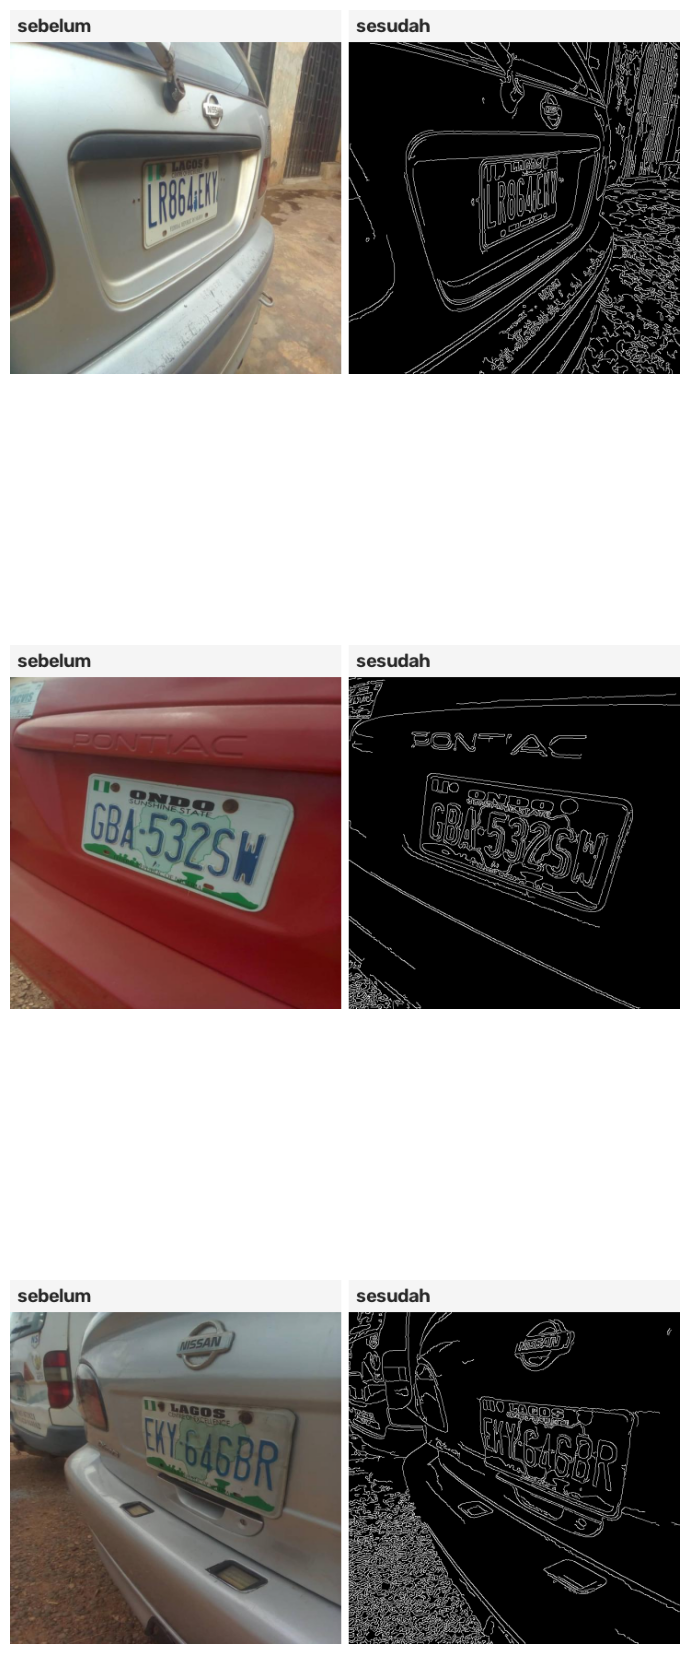

In [15]:
FOLDER_FIGUR.mkdir(parents=True, exist_ok=True)
for p in berkas[:12]:
    asli = util.ubah_ukuran_maks(util.baca_citra(p), 1024)
    util.simpan_sebelum_sesudah(asli, praproses(asli), FOLDER_FIGUR / f"pra_{p.stem}.png")
contoh = sorted(FOLDER_FIGUR.glob("pra_*.png"))[:3]
print(len(list(FOLDER_FIGUR.glob("pra_*.png"))), "gambar di", FOLDER_FIGUR)
util.tampil(*[util.baca_citra(f) for f in contoh], kolom=1, ukuran=7)

## Simpan ke GitHub

1. **Runtime → Restart session and run all**, pastikan tidak ada error.
2. **File → Save a copy in GitHub** → repo `Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t1` → **branch Anda** (bukan `main`) → path tetap `notebooks/01_dataset_preprocessing.ipynb`.
3. Buka *pull request* ke `main` di github.com. Langkah lengkap: `PANDUAN.md`.